<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory spatial data analysis of multidimensional poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

Is poverty in one municipality similar to poverty in its neighbours, and did that change as poverty fell? This notebook answers both questions for the Multidimensional Poverty Index (MPI) of Bolivia's 343 municipalities and indigenous autonomies, measured from the population censuses of 2012 and 2024 by the *Atlas de los ODS en Bolivia 2026* (SDSN Bolivia). Step by step:

1. **Load and map** the data for both periods with `geo4bolivia`
2. **Spatial weights and spatial lags**: who are the neighbours, and how poor are they?
3. **Global spatial dependence**: Moran's I in 2012 and 2024
4. **Local spatial dependence**: LISA clusters and outliers in both periods, and how they moved
5. **Combined figure**: the Moran scatterplot next to the cluster map, for 2024

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mapclassify as mc

from libpysal import weights
from esda.moran import Moran, Moran_Local
from splot.esda import lisa_cluster
from splot.libpysal import plot_spatial_weights

import geo4bolivia as geo

warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it
sns.set_theme(style="whitegrid")
SEED = 12345

## 1. Load the data

`geo.load(..., geometry=True)` returns the poverty index with the municipal boundaries and names. The MPI runs from 0 to 1, and **higher values mean more poverty**. The Atlas gives it for two periods, stored as the years 2012 and 2024; `wide=` puts them side by side, one column per year. We add the department of each municipality and a poverty rank for 2024 (1 = poorest), and project the map to the observatory's equal-area projection, so that distances and areas are in metres.

In [3]:
YEARS = [2012, 2024]
MPI = {year: f"mpi_{year}" for year in YEARS}          # column names

gdf = geo.load("sdg01", variables="sdg1_2_mpi", years=2024, geometry=True)[["geo_id", "name", "geometry"]]
wide = geo.load("sdg01", variables="sdg1_2_mpi", wide="sdg1_2_mpi")
gdf = gdf.merge(wide.rename(columns={f"sdg1_2_mpi{y}": MPI[y] for y in YEARS}), on="geo_id")

units = geo.units("municipality")[["geo_id", "department_id"]]
dep_names = geo.units("department").set_index("geo_id")["name"]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(dep_names)
gdf["rank_2024"] = gdf[MPI[2024]].rank(ascending=False, method="min").astype(int)

gdf = gdf[["geo_id", "name", "department", *MPI.values(), "rank_2024", "geometry"]].to_crs(geo.config()["equal_area_crs"])
print(len(gdf), "municipalities and indigenous autonomies")
gdf.head()

343 municipalities and indigenous autonomies


,geo_id,name,department,mpi_2012,mpi_2024,rank_2024,geometry
0,BO-01-01-01,Azurduy,Chuquisaca,0.512,0.187,7,"POLYGON ((21748.153 -439187.901, 21583.382 -43..."
1,BO-01-01-02,Tarvita,Chuquisaca,0.452,0.133,29,"POLYGON ((-22428.892 -364087.956, -22792.117 -..."
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.267,0.056,160,"POLYGON ((50112.168 -295041.407, 49559.694 -29..."
3,BO-01-03-01,Huacareta,Chuquisaca,0.346,0.071,112,"POLYGON ((35331.312 -486863.957, 35115.188 -48..."
4,BO-01-03-02,Monteagudo,Chuquisaca,0.212,0.043,210,"POLYGON ((70798.318 -431213.236, 70721.787 -43..."


In [4]:
gdf[list(MPI.values())].describe().round(3)

,mpi_2012,mpi_2024
count,343.000,343.000
mean,0.234,0.063
std,0.106,0.044
min,0.018,0.003
25%,0.153,0.030
50%,0.227,0.053
75%,0.306,0.083
max,0.563,0.296


Did any municipality become poorer, and did the ranking change?

In [5]:
change = gdf[MPI[2024]] - gdf[MPI[2012]]
print(f"Mean MPI fell by {1 - gdf[MPI[2024]].mean() / gdf[MPI[2012]].mean():.0%}; "
      f"municipalities where it rose: {(change > 0).sum()}")
print(f"Rank (Spearman) correlation between 2012 and 2024: "
      f"{gdf[MPI[2012]].corr(gdf[MPI[2024]], method='spearman'):.2f}")

Mean MPI fell by 73%; municipalities where it rose: 0
Rank (Spearman) correlation between 2012 and 2024: 0.86


Department boundaries, with a label point inside each, for the maps:

In [6]:
departments = geo.boundaries("department").to_crs(gdf.crs)
departments["label_point"] = departments.representative_point()

## 2. Map the data

First both periods on one continuous colour scale, which shows how much poverty fell; then three classes per period found by the Fisher-Jenks natural-breaks algorithm, which show where poverty is relatively high in each period.

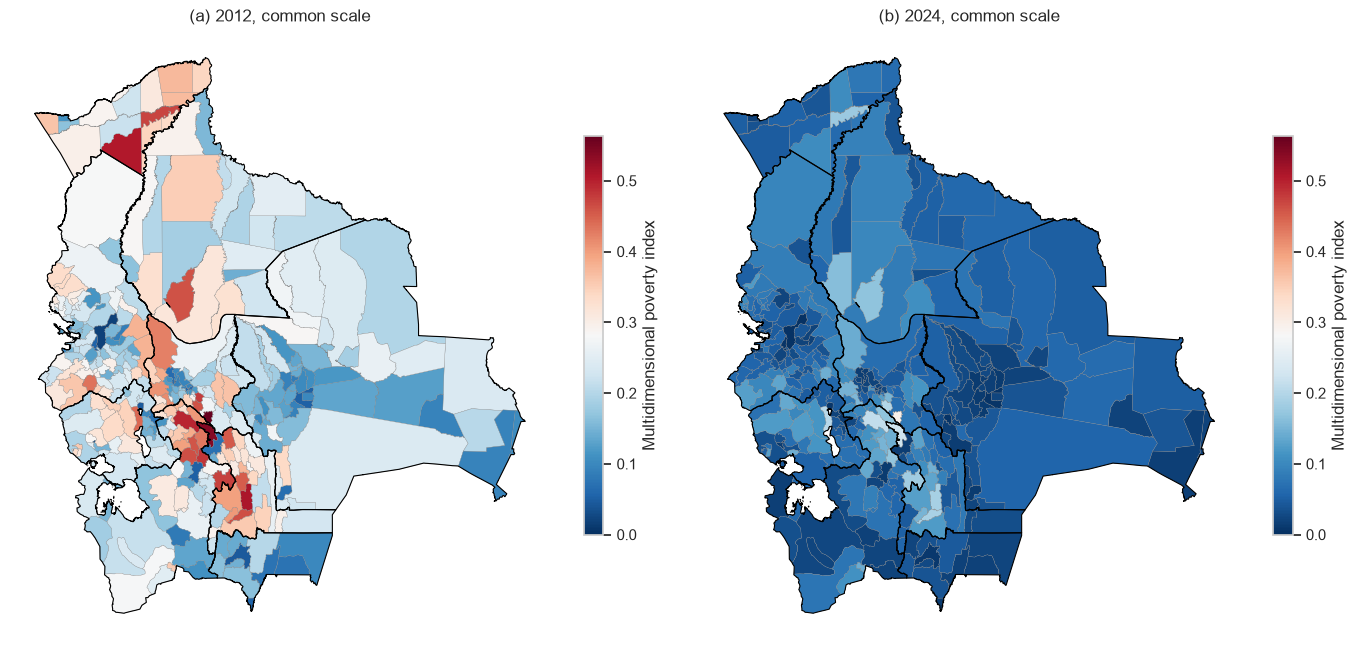

In [7]:
def add_departments(ax, labels=True):
    departments.boundary.plot(ax=ax, color="black", linewidth=0.8)
    if labels:
        for _, row in departments.iterrows():
            ax.annotate(row["name"], xy=(row["label_point"].x, row["label_point"].y), ha="center", fontsize=8,
                        bbox={"facecolor": "white", "alpha": 0.8, "pad": 1.5, "edgecolor": "none"})
    ax.set_axis_off()

vmax = gdf[MPI[2012]].max()
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, year in zip(axes, YEARS):
    gdf.plot(column=MPI[year], cmap="RdBu_r", vmin=0, vmax=vmax, edgecolor="grey", linewidth=0.2, legend=True,
             legend_kwds={"label": "Multidimensional poverty index", "shrink": 0.6}, ax=ax)
    ax.set_title(f"({'ab'[YEARS.index(year)]}) {year}, common scale")
    add_departments(ax, labels=False)
plt.tight_layout()
plt.show()

In [8]:
for year in YEARS:
    fj = mc.FisherJenks(gdf[MPI[year]], k=3)
    print(year, "upper bounds:", fj.bins.round(3), "| municipalities per class:", fj.counts)

2012 upper bounds: [0.179 0.308 0.563] | municipalities per class: [112 148  83]
2024 upper bounds: [0.052 0.11  0.296] | municipalities per class: [166 132  45]


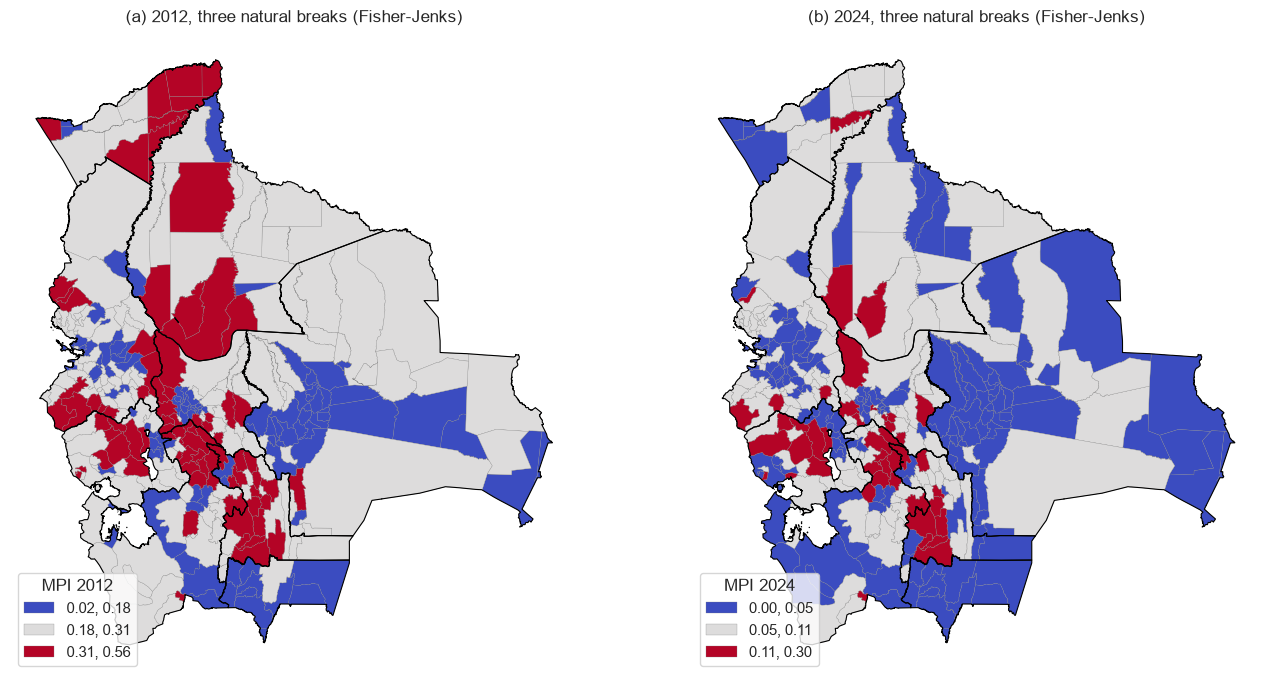

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, year in zip(axes, YEARS):
    gdf.plot(column=MPI[year], scheme="FisherJenks", k=3, cmap="coolwarm", edgecolor="grey", linewidth=0.2,
             legend=True, legend_kwds={"title": f"MPI {year}", "loc": "lower left"}, ax=ax)
    ax.set_title(f"({'ab'[YEARS.index(year)]}) {year}, three natural breaks (Fisher-Jenks)")
    add_departments(ax, labels=False)
plt.tight_layout()
plt.show()

Poverty fell everywhere. The mean MPI dropped from 0.234 in 2012 to 0.063 in 2024 (by 73%), the median from 0.227 to 0.053, and no municipality became poorer. The ranking, however, barely moved: the rank correlation between the two periods is 0.86, and the poorest unit in both is TIOC-Raqaypampa (Cochabamba; 0.563, then 0.296).

The natural breaks show where poverty stays relatively high. In 2012 the top class (MPI above 0.31, 83 units) covers the belt where Chuquisaca, Potosí and Cochabamba meet, most of Pando and much of the Oruro and La Paz highlands. In 2024 the top class (above 0.11) is smaller, 45 units, and concentrated in that belt (11 in Potosí and 9 each in Chuquisaca and Cochabamba) and in Oruro (9); Pando, which had 9 units in the top class in 2012, keeps only San Pedro. The least poor class holds the main cities, Santa Cruz (48 of its 56 units in 2024) and Tarija (all 11).

## 3. Spatial weights and spatial lags

A **spatial weights matrix** $W$ says who is a neighbour of whom. Here each municipality's neighbours are its 6 nearest municipalities (by the distance between centroids), built on all 343 units. With k-nearest neighbours every unit has neighbours, so there are no islands to handle. The matrix is **row-standardised**, so each row sums to one and the neighbours have equal weight. The same matrix serves both periods.

In [10]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"
print(f"{W.n} municipalities, {W.mean_neighbors:.0f} neighbours each, {W.s0:.0f} = sum of the weights")
print(f"islands: {len(W.islands)}; connected components: {W.n_components}")

343 municipalities, 6 neighbours each, 343 = sum of the weights
islands: 0; connected components: 1


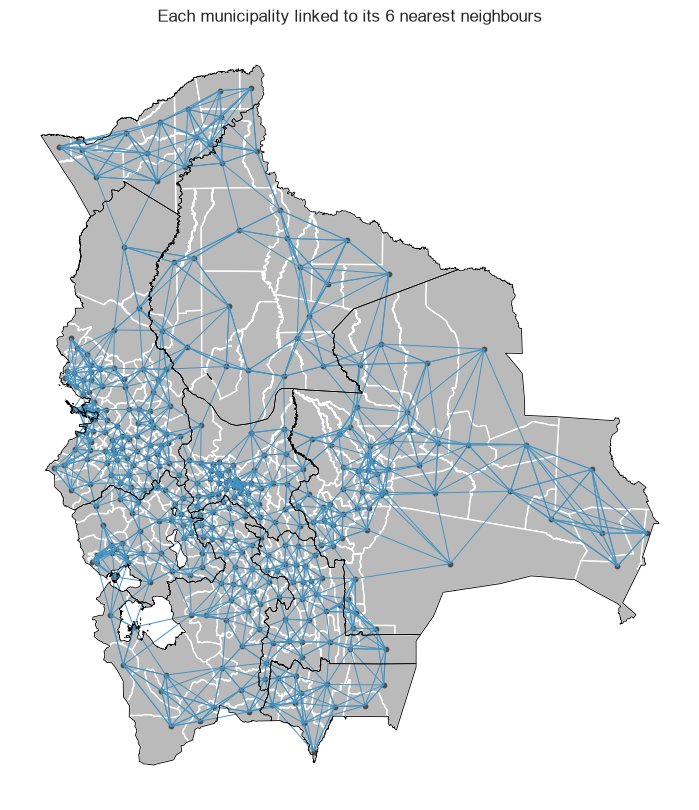

In [11]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_spatial_weights(W, gdf, ax=ax)
departments.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_title("Each municipality linked to its 6 nearest neighbours")
plt.show()

The **spatial lag** $Wy$ of the MPI is the average poverty of each municipality's neighbours:

In [12]:
LAG = {year: f"W_mpi_{year}" for year in YEARS}
for year in YEARS:
    gdf[LAG[year]] = weights.lag_spatial(W, gdf[MPI[year]])
gdf[["name", "department", MPI[2012], LAG[2012], MPI[2024], LAG[2024]]].round(3).head(10)

,name,department,mpi_2012,W_mpi_2012,mpi_2024,W_mpi_2024
0,Azurduy,Chuquisaca,0.512,0.377,0.187,0.122
1,Tarvita,Chuquisaca,0.452,0.380,0.133,0.125
2,Villa Serrano,Chuquisaca,0.267,0.277,0.056,0.055
3,Huacareta,Chuquisaca,0.346,0.347,0.071,0.099
4,Monteagudo,Chuquisaca,0.212,0.314,0.043,0.088
5,Huacaya (Autonomía Guaraní Chaqueño de Huacaya),Chuquisaca,0.298,0.218,0.029,0.037
6,Macharetí,Chuquisaca,0.229,0.213,0.031,0.033
7,Villa Vaca Guzmán,Chuquisaca,0.261,0.241,0.080,0.039
8,Camargo,Chuquisaca,0.198,0.339,0.045,0.109
9,Incahuasi,Chuquisaca,0.462,0.369,0.191,0.117


For Azurduy (Chuquisaca), one of the poorest municipalities, the MPI fell from 0.512 to 0.187, and the average of its 6 neighbours from 0.377 to 0.122: in both periods its neighbours are poor, but less so than Azurduy itself.

## 4. Global spatial dependence

Plotting each municipality's poverty against the poverty of its neighbours shows whether poor municipalities tend to have poor neighbours:

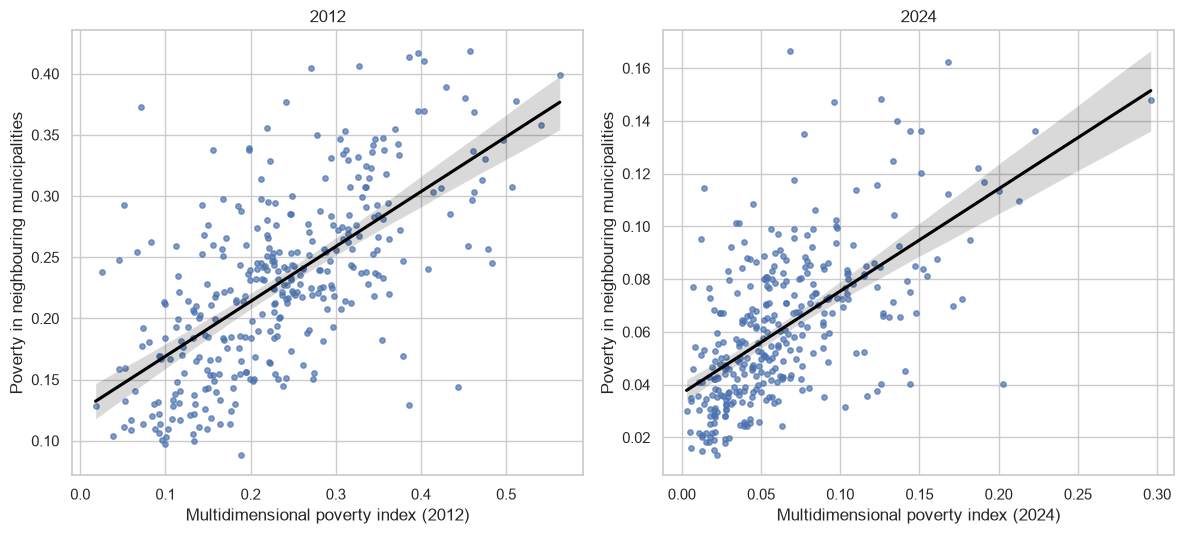

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, year in zip(axes, YEARS):
    sns.regplot(data=gdf, x=MPI[year], y=LAG[year], scatter_kws={"s": 15, "alpha": 0.7},
                line_kws={"color": "black"}, ax=ax)
    ax.set(xlabel=f"Multidimensional poverty index ({year})", ylabel="Poverty in neighbouring municipalities",
           title=str(year))
plt.tight_layout()
plt.show()

**Moran's I** summarises this relationship in one number: with row-standardised weights it is the slope of the regression of the standardised spatial lag on the standardised variable. Values near 0 mean no spatial pattern; positive values mean that similar values cluster. Its pseudo p-value compares it with 999 random reshuffles of the values across the map.

In [14]:
np.random.seed(SEED)
globalMoran = {year: Moran(gdf[MPI[year]], W, permutations=999) for year in YEARS}

pd.DataFrame({year: {"Moran's I": m.I, "expected I": m.EI, "pseudo p-value": m.p_sim, "z": m.z_sim}
              for year, m in globalMoran.items()}).round(3)

,2012,2024
Moran's I,0.448,0.388
expected I,-0.003,-0.003
pseudo p-value,0.001,0.001
z,15.026,13.595


Moran's I is 0.45 in 2012 and 0.39 in 2024, far above its expected value of about 0 under spatial randomness. In both periods none of the 999 random reshuffles produced a value as large (pseudo p-value 0.001, the smallest possible with 999 permutations). Poverty is strongly and positively spatially autocorrelated in both periods: poor municipalities tend to have poor neighbours. Clustering weakened somewhat as poverty fell, but it remains strong.

## 5. Local spatial dependence

Moran's I is one number for the whole country. **Local Moran's I** (LISA, Local Indicators of Spatial Association) computes one statistic per municipality and tests it with permutations. Each significant municipality falls in one of four groups:

| Group | The municipality is | Its neighbours are | Meaning |
| --- | --- | --- | --- |
| High-high | poor | poor | **poverty hotspot** |
| Low-low | less poor | less poor | **cluster of low poverty** |
| High-low | poor | less poor | poor outlier |
| Low-high | less poor | poor | less poor outlier |

"High" and "low" are relative to the national mean of each period, so a 2024 hotspot is poor by 2024 standards.

In [15]:
moranLocal = {year: Moran_Local(gdf[MPI[year]], W, permutations=999, seed=SEED) for year in YEARS}

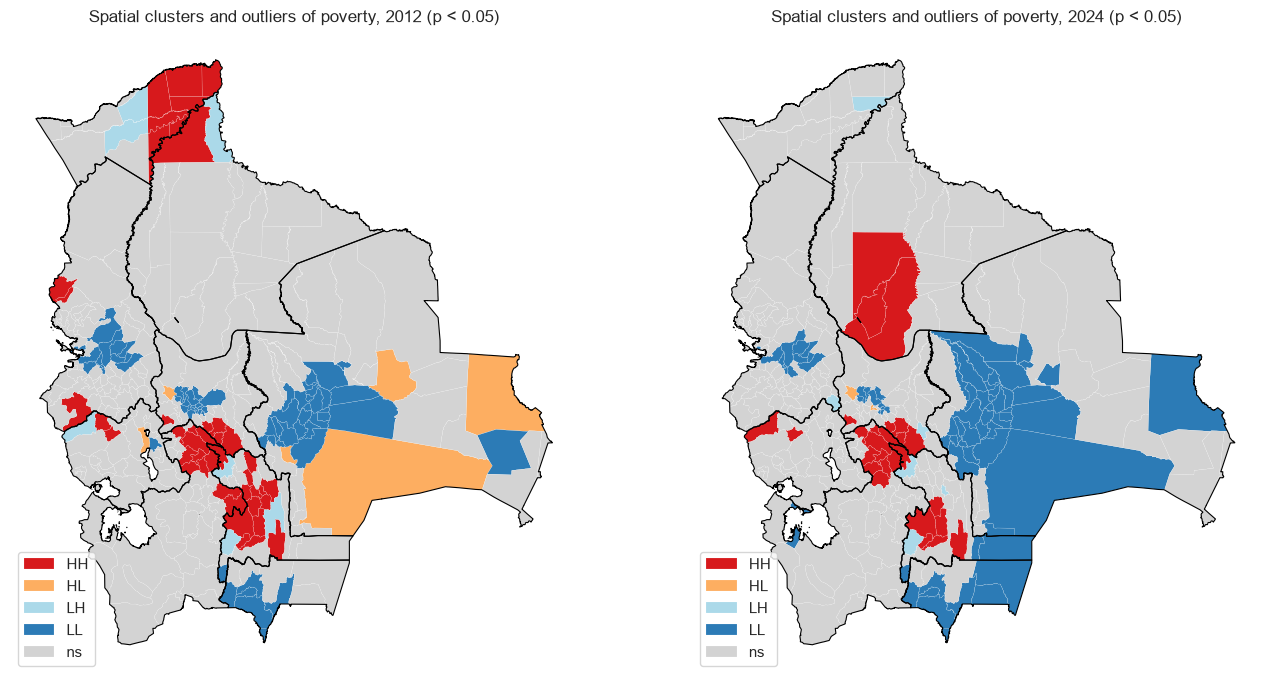

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, year in zip(axes, YEARS):
    lisa_cluster(moranLocal[year], gdf, p=0.05, legend_kwds={"loc": "lower left"}, ax=ax)
    add_departments(ax, labels=False)
    ax.set_title(f"Spatial clusters and outliers of poverty, {year} (p < 0.05)")
plt.tight_layout()
plt.show()

The same classification as columns, to count and list the municipalities in each group:

In [17]:
quadrants = {1: "High-high", 2: "Low-high", 3: "Low-low", 4: "High-low"}
CLUSTER = {year: f"cluster_{year}" for year in YEARS}
for year in YEARS:
    lm = moranLocal[year]
    gdf[f"lisa_p_{year}"] = lm.p_sim
    gdf[CLUSTER[year]] = np.where(lm.p_sim < 0.05, pd.Series(lm.q).map(quadrants), "Not significant")

order = ["High-high", "Low-low", "High-low", "Low-high", "Not significant"]
pd.DataFrame({year: gdf[CLUSTER[year]].value_counts() for year in YEARS}).reindex(order)

,2012,2024
High-high,43,27
Low-low,70,71
High-low,7,3
Low-high,7,6
Not significant,216,236


How did municipalities move between groups? Rows are the 2012 group, columns the 2024 group:

In [18]:
pd.crosstab(gdf[CLUSTER[2012]], gdf[CLUSTER[2024]], margins=True, margins_name="Total")

cluster_2024,High-high,High-low,Low-high,Low-low,Not significant,Total
cluster_2012,,,,,,
High-high,22,0,2,0,19,43
High-low,0,2,0,3,2,7
Low-high,1,0,2,0,4,7
Low-low,0,1,0,54,15,70
Not significant,4,0,2,14,196,216
Total,27,3,6,71,236,343


The groups by department in 2024:

In [19]:
pd.crosstab(gdf["department"], gdf[CLUSTER[2024]], margins=True, margins_name="Total")

cluster_2024,High-high,High-low,Low-high,Low-low,Not significant,Total
department,,,,,,
Beni,3,0,0,0,17,20
Chuquisaca,7,0,3,3,16,29
Cochabamba,5,2,1,11,29,48
La Paz,0,1,1,11,74,87
Oruro,2,0,0,0,33,35
Pando,0,0,1,0,14,15
Potosí,10,0,0,1,31,42
Santa Cruz,0,0,0,37,19,56
Tarija,0,0,0,8,3,11


The spatial outliers in 2024, municipalities that differ significantly from their neighbours:

In [20]:
outliers = gdf[CLUSTER[2024]].isin(["High-low", "Low-high"])
(gdf[outliers].sort_values([CLUSTER[2024], MPI[2024]], ascending=[True, False])
    [["name", "department", CLUSTER[2024], MPI[2024], LAG[2024], "rank_2024", "lisa_p_2024", CLUSTER[2012]]].round(3))

,name,department,cluster_2024,mpi_2024,W_mpi_2024,rank_2024,lisa_p_2024,cluster_2012
54,Arbieto,Cochabamba,High-low,0.117,0.036,41,0.035,Low-low
35,Morochata,Cochabamba,High-low,0.103,0.031,56,0.017,High-low
154,Tito Yupanqui,La Paz,High-low,0.090,0.035,73,0.033,High-low
130,Colquiri,La Paz,Low-high,0.061,0.097,141,0.049,Not significant
223,Villa Nueva,Pando,Low-high,0.056,0.099,160,0.041,High-high
8,Camargo,Chuquisaca,Low-high,0.045,0.109,201,0.021,Low-high
38,Omereque,Cochabamba,Low-high,0.036,0.101,239,0.036,Not significant
18,Alcalá,Chuquisaca,Low-high,0.034,0.101,248,0.032,High-high
13,Sucre,Chuquisaca,Low-high,0.014,0.115,323,0.010,Low-high


At the 5% level, 127 of the 343 units belong to a significant group in 2012 and 107 in 2024:

- **Poverty hotspots (High-high) fell from 43 to 27.** In 2012 they were in Chuquisaca (14), Potosí (11), Pando (7), Cochabamba (5), La Paz (3), Oruro (2) and Beni (1). In 2024 they are concentrated in the belt where Chuquisaca, Potosí and Cochabamba meet (10 in Potosí, 7 in Chuquisaca, 5 in Cochabamba, among them TIOC-Raqaypampa and San Pedro de Macha), plus Choquecota and Curahuara de Carangas in Oruro and three units in Beni (San Ignacio, Santa Ana and the new TIOC-Territorio Indígena Multiétnico). The Pando hotspot has disappeared: none of Pando's units is a hotspot in 2024. Of the 43 hotspots of 2012, 22 are still hotspots and 19 are no longer significant.
- **Low-poverty clusters (Low-low) stayed at about 70** (70 in 2012, 71 in 2024), but moved towards the lowlands: Santa Cruz has 37 in 2024 (27 in 2012), while Cochabamba has 11 (20) and La Paz 11 (15). Tarija has 8 of its 11 municipalities. 54 units are Low-low in both periods.
- **Outliers fell from 14 to 9.** In 2024, three poorer municipalities have less poor neighbours (High-low: Arbieto and Morochata in Cochabamba, Tito Yupanqui in La Paz), and six less poor municipalities have poorer neighbours (Low-high), among them the capital Sucre (MPI 0.014, neighbours 0.115), Camargo and Alcalá in Chuquisaca, and Villa Nueva in Pando.

With 343 local tests, some significant results are expected by chance alone, so treat isolated significant municipalities with care; the large contiguous clusters are the robust finding.

## 6. Combined figure

The 2024 Moran scatterplot coloured by LISA group, next to the cluster map. The dashed lines are the means of the MPI and of its spatial lag, which split the plot into the four quadrants.

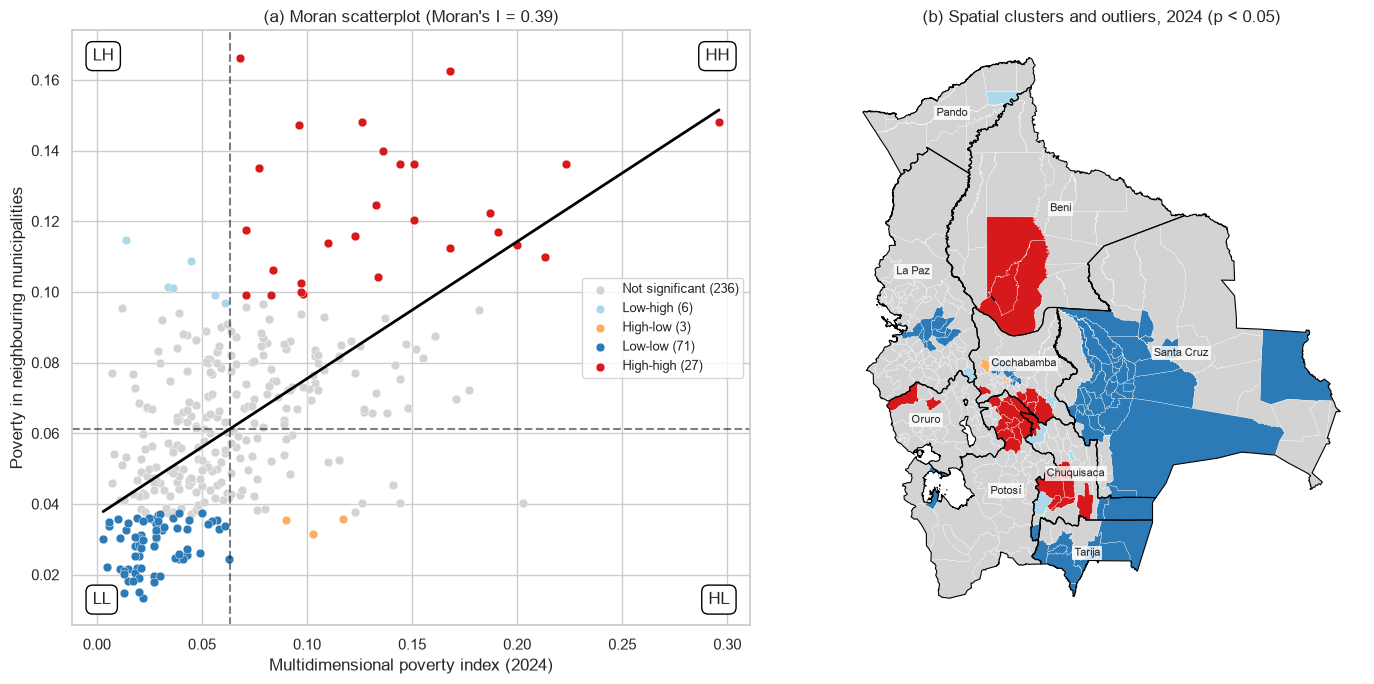

In [21]:
colors = {"High-high": "#d7191c", "High-low": "#fdae61", "Low-high": "#abd9e9", "Low-low": "#2c7bb6",
          "Not significant": "#d3d3d3"}
x, y, cluster = MPI[2024], LAG[2024], CLUSTER[2024]

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.1]})

# (a) Moran scatterplot
ax = axes[0]
sns.regplot(data=gdf, x=x, y=y, scatter=False, ci=None, line_kws={"color": "black", "lw": 2}, ax=ax)
for group in ["Not significant", "Low-high", "High-low", "Low-low", "High-high"]:
    d = gdf[gdf[cluster] == group]
    ax.scatter(d[x], d[y], s=40, color=colors[group], label=f"{group} ({len(d)})",
               edgecolor="white", linewidth=0.3)
ax.axvline(gdf[x].mean(), color="black", alpha=0.5, linestyle="--")
ax.axhline(gdf[y].mean(), color="black", alpha=0.5, linestyle="--")
box = dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1)
for text, (tx, ty) in {"HH": (0.97, 0.97), "LH": (0.03, 0.97), "LL": (0.03, 0.03), "HL": (0.97, 0.03)}.items():
    ax.text(tx, ty, text, transform=ax.transAxes, ha="right" if tx > 0.5 else "left",
            va="top" if ty > 0.5 else "bottom", bbox=box)
ax.set(xlabel="Multidimensional poverty index (2024)", ylabel="Poverty in neighbouring municipalities",
       title=f"(a) Moran scatterplot (Moran's I = {globalMoran[2024].I:.2f})")
ax.legend(loc="center right", fontsize=9)

# (b) cluster map
ax = axes[1]
gdf.plot(color=gdf[cluster].map(colors), edgecolor="white", linewidth=0.2, ax=ax)
add_departments(ax)
ax.set_title("(b) Spatial clusters and outliers, 2024 (p < 0.05)")

plt.tight_layout()
plt.show()

## Summary

- Multidimensional poverty fell by 73% between 2012 and 2024 (mean MPI 0.234 to 0.063) and in every one of the 343 units, but the ranking is stable (rank correlation 0.86).
- Poverty is strongly spatially clustered in both periods: Moran's I = 0.45 in 2012 and 0.39 in 2024 (pseudo p-value 0.001) with 6-nearest-neighbour weights.
- Poverty hotspots fell from 43 to 27 and now concentrate where Chuquisaca, Potosí and Cochabamba meet; the Pando hotspot of 2012 has disappeared. Low-poverty clusters (70, then 71) shifted towards Santa Cruz and Tarija.
- Some capitals stand out as less poor islands among poorer neighbours (Sucre in both periods).
- The companion notebook [`esda_dependence`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb) compares map classifications and repeats the analysis at the 10% level; [`esda_inequality`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_inequality.ipynb) measures how unequal poverty is and how that changed.